# within-country change and a two-measure regression

My other tests compare different countries pooled across years, so "richer" can partly mean "later". This notebook checks whether the wealth and health link still holds (1) once I control for the year, (2) inside each country over time, and (3) how much of it runs through child survival.

In [1]:
# Reads: ../data/clean_joined.csv | Saves: nothing
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf

sns.set_theme(style="whitegrid")
df = pd.read_csv(r"C:\Users\admin\Desktop\Captoneproject-pydata\data\clean_joined.csv")
print("Rows:", len(df), "| Countries:", df["Entity"].nunique())

Rows: 10429 | Countries: 163


## 1. Does income still matter once I control for the year?

In [3]:
# model A: life expectancy from log GDP only
# model B: add the year, so the shared rise over time is taken out
# standard errors are clustered by country, because the same country appears many times
a = smf.ols("life_exp ~ log_gdp", data=df).fit(cov_type="cluster", cov_kwds={"groups": df["Entity"]})
b = smf.ols("life_exp ~ log_gdp + Year", data=df).fit(cov_type="cluster", cov_kwds={"groups": df["Entity"]})

for name, m in [("A: log GDP only", a), ("B: log GDP + year", b)]:
    ci = m.conf_int().loc["log_gdp"]
    print(f"{name}: log GDP coefficient = {m.params['log_gdp']:.2f} (95% CI {ci[0]:.2f} to {ci[1]:.2f}), R squared = {m.rsquared:.3f}")
print(f"\nIn model B, each extra year adds {b.params['Year']:.3f} years of life expectancy at the same income")
print(f"Doubling income goes with {b.params['log_gdp'] * np.log(2):.1f} more years of life expectancy in model B")

A: log GDP only: log GDP coefficient = 8.43 (95% CI 7.94 to 8.91), R squared = 0.689
B: log GDP + year: log GDP coefficient = 7.58 (95% CI 7.06 to 8.09), R squared = 0.748

In model B, each extra year adds 0.153 years of life expectancy at the same income
Doubling income goes with 5.3 more years of life expectancy in model B


## 2. Inside each country: did faster growth go with bigger gains?

In [4]:
# for each country, the change from 1960 to 2019 (both years needed)
wide = df[df["Year"].isin([1960, 2019])].pivot(index="Entity", columns="Year", values=["log_gdp", "life_exp", "log_child_mort"]).dropna()
change = pd.DataFrame({
    "gdp_growth": wide[("log_gdp", 2019)] - wide[("log_gdp", 1960)],          # change in log GDP
    "life_gain": wide[("life_exp", 2019)] - wide[("life_exp", 1960)],         # years gained
    "mort_change": wide[("log_child_mort", 2019)] - wide[("log_child_mort", 1960)],
})
r_life, p_life = stats.pearsonr(change["gdp_growth"], change["life_gain"])
r_mort, p_mort = stats.pearsonr(change["gdp_growth"], change["mort_change"])
print("Countries with data in both 1960 and 2019:", len(change))
print(f"Income growth vs life expectancy gain:   r = {r_life:.2f}, p = {'< 0.001' if p_life < 0.001 else round(p_life, 3)}")
print(f"Income growth vs change in log child mortality: r = {r_mort:.2f}, p = {'< 0.001' if p_mort < 0.001 else round(p_mort, 3)}")
print(f"Countries whose income fell but life expectancy still rose: {int(((change['gdp_growth'] < 0) & (change['life_gain'] > 0)).sum())}")

Countries with data in both 1960 and 2019: 125
Income growth vs life expectancy gain:   r = 0.15, p = 0.094
Income growth vs change in log child mortality: r = -0.53, p = < 0.001
Countries whose income fell but life expectancy still rose: 5


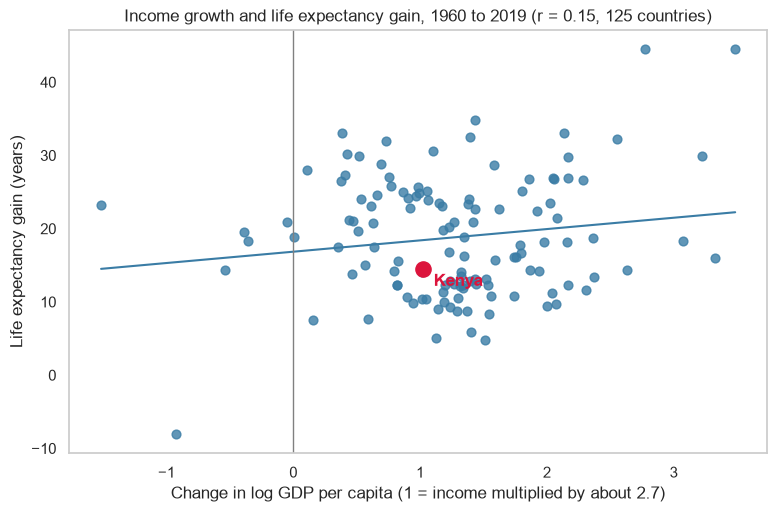

In [5]:
plt.figure(figsize=(9, 5.5))
plt.scatter(change["gdp_growth"], change["life_gain"], s=40, color="#3a7ca5", alpha=0.8)
slope, intercept = np.polyfit(change["gdp_growth"], change["life_gain"], 1)
xs = np.linspace(change["gdp_growth"].min(), change["gdp_growth"].max(), 100)
plt.plot(xs, slope * xs + intercept, color="#3a7ca5")
if "Kenya" in change.index:
    k = change.loc["Kenya"]
    plt.scatter(k["gdp_growth"], k["life_gain"], s=120, color="crimson", zorder=3)
    plt.annotate("Kenya", (k["gdp_growth"], k["life_gain"]), xytext=(8, -12), textcoords="offset points", color="crimson", fontweight="bold")
plt.axvline(0, color="gray", linewidth=1)
plt.title(f"Income growth and life expectancy gain, 1960 to 2019 (r = {r_life:.2f}, {len(change)} countries)")
plt.xlabel("Change in log GDP per capita (1 = income multiplied by about 2.7)")
plt.ylabel("Life expectancy gain (years)")
plt.grid(False)
plt.show()

In [6]:
# country fixed effects: compare each country only with itself over time, and control for the year
fe = smf.ols("life_exp ~ log_gdp + C(Entity) + C(Year)", data=df).fit(cov_type="cluster", cov_kwds={"groups": df["Entity"]})
ci = fe.conf_int().loc["log_gdp"]
print(f"Within-country log GDP coefficient = {fe.params['log_gdp']:.2f} (95% CI {ci[0]:.2f} to {ci[1]:.2f})")
print(f"Pooled coefficient (model A) = {a.params['log_gdp']:.2f}")

Within-country log GDP coefficient = 1.08 (95% CI -0.23 to 2.39)
Pooled coefficient (model A) = 8.43


## 3. How much of the wealth link runs through child survival?

In [7]:
c = smf.ols("life_exp ~ log_gdp + log_child_mort + Year", data=df).fit(cov_type="cluster", cov_kwds={"groups": df["Entity"]})
print(c.summary().tables[1])
share = 1 - c.params["log_gdp"] / b.params["log_gdp"]
print(f"\nAdding child mortality shrinks the log GDP coefficient from {b.params['log_gdp']:.2f} to {c.params['log_gdp']:.2f}")
print(f"So about {share:.0%} of the income link with life expectancy goes together with lower child mortality")
print(f"R squared rises from {b.rsquared:.3f} to {c.rsquared:.3f}")

                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         51.7151     23.765      2.176      0.030       5.136      98.294
log_gdp            1.2551      0.295      4.261      0.000       0.678       1.832
log_child_mort    -7.6998      0.349    -22.086      0.000      -8.383      -7.016
Year               0.0064      0.011      0.563      0.573      -0.016       0.028

Adding child mortality shrinks the log GDP coefficient from 7.58 to 1.26
So about 83% of the income link with life expectancy goes together with lower child mortality
R squared rises from 0.748 to 0.876


## What this adds

- **Controlling for the year:** income still matters at the same point in time. Doubling income goes with about 5.3 more years of life expectancy (log GDP coefficient 7.58, 95% CI 7.06 to 8.09, standard errors clustered by country).
- **Within countries, the link is much weaker.** Across 125 countries with data in 1960 and 2019, faster income growth barely went with bigger life expectancy gains (r = 0.15, p = 0.094). With country and year fixed effects the coefficient falls from 8.43 to 1.08 and is not significant (95% CI -0.23 to 2.39). Faster growth did go with faster falls in child mortality (r = -0.53, p < 0.001).
- **Child survival:** adding log child mortality shrinks the income coefficient from 7.58 to 1.26, so about 83% of the income link travels together with lower child mortality.

**What it means for my hypothesis:** the strong link is mostly *between* countries. Inside a country over time, life expectancy rose almost everywhere whatever the growth rate, which supports the point that growth alone is not enough and health improvements (especially child survival) matter directly.

**Cautions:** still observational, so these are patterns, not causes. Health can also drive growth, and other factors (education, conflict, HIV) are not in the data. 1960 to 2019 is one window; other windows could differ.